# Evaluation 2 – Response time

How long a question takes from the user's point of view (`wall_ms`), and how that time is split over the pipeline
steps.

| part | column |
|---|---|
| Classify – the LLM picks the query type | `ms_classify` |
| Extract – the LLM pulls out places, years, attributes | `ms_extract` |
| SQL – the LLM writes the SQL, it is checked and run (incl. retries) | `ms_sql` |
| KQML – the exchange with the other agent | `ms_kqml` |
| Other agent work – merging and formatting the answer | `ms_agent − the four steps` |
| Outside the agent – HTTP and the test harness (about 2 s, the same for every ask) | `wall_ms − ms_agent` |

The questions are grouped into the **five scenario categories** of the thesis (the same grouping as notebook 01):

| # | category | scenarios | query types in the test set | questions |
|---|---|---|---|---|
| 1 | Data missingness | 1–8 | DATA_LOOKUP | 18 |
| 2 | Geometry missingness | 9–12 | GEOMETRY_LOOKUP | 12 |
| 3 | Constructive operations | 13–16 | SPATIAL_OPERATION | 17 |
| 4 | Relationships | 17–19 | SPATIAL_ADJACENCY, SPATIAL_DIRECTION, SPATIAL_DISTANCE | 34 |
| 5 | Query delegation | 20 | SPATIAL_RELATIONSHIP_BUFFER (city lists in a zone) | 14 |

The 5 out-of-scope questions (UNRELATED) are left out: 4 models × 95 questions × 2 agents × 5 repetitions = 3 800 asks.

**Note:** the Qwen models ran on local hardware, GPT-4o mini and Claude Haiku through their APIs, so the times compare
the whole setup (model + hardware/network), not the models alone.

In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

DATA_DIR = Path("..") / "data"
OUT_DIR = Path("outputs") / "02_response_time"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["gpt-4o-mini", "claude-haiku", "qwen3-8b", "qwen3-8b-lora"]
MODEL_LABEL = {"gpt-4o-mini": "GPT-4o mini", "claude-haiku": "Claude Haiku 5.5",
               "qwen3-8b": "Qwen3-8B", "qwen3-8b-lora": "Qwen3-8B + QLoRA"}
MODEL_COLOR = {"gpt-4o-mini": "#2a78d6", "claude-haiku": "#eb6834",
               "qwen3-8b": "#1baf7a", "qwen3-8b-lora": "#eda100"}

CATEGORIES = ["1 Data missingness", "2 Geometry missingness", "3 Constructive operations",
              "4 Relationships", "5 Query delegation"]
CATEGORY_OF_TYPE = {
    "DATA_LOOKUP": "1 Data missingness",
    "GEOMETRY_LOOKUP": "2 Geometry missingness",
    "SPATIAL_OPERATION": "3 Constructive operations",
    "SPATIAL_ADJACENCY": "4 Relationships",
    "SPATIAL_DIRECTION": "4 Relationships",
    "SPATIAL_DISTANCE": "4 Relationships",
    "SPATIAL_RELATIONSHIP_BUFFER": "5 Query delegation",
}
# the two questions without a query type in the answer key
CATEGORY_OF_QID = {"q-ee68a1a070": "2 Geometry missingness",   # "Give me the point for Hamburg, the city"
                   "q-f21a844357": "5 Query delegation"}       # "Show me cities within 60 km of Hannover?"

files = [f for f in DATA_DIR.glob("evaluation_per_model_runs-*/evaluation_*_runs-*.csv") if "summary" not in f.name]
df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in files], ignore_index=True)
df["category"] = df["expected_category"].map(CATEGORY_OF_TYPE).fillna(df["qid"].map(CATEGORY_OF_QID))
df = df[df["category"].notna()].copy()            # drops the 5 UNRELATED questions
df["model"] = pd.Categorical(df["model"], categories=MODELS, ordered=True)
df["category"] = pd.Categorical(df["category"], categories=CATEGORIES, ordered=True)

# all times in seconds
STEPS = [("ms_classify", "Classify", "#2a78d6"), ("ms_extract", "Extract", "#eb6834"),
         ("ms_sql", "SQL", "#1baf7a"), ("ms_kqml", "KQML", "#eda100"),
         ("ms_other", "Other agent work", "#e87ba4"), ("ms_outside", "Outside agent", "#a3a29c")]
df["ms_other"] = df["ms_agent"] - df[["ms_classify", "ms_extract", "ms_sql", "ms_kqml"]].sum(axis=1)
df["ms_outside"] = df["wall_ms"] - df["ms_agent"]
for col, label, _ in STEPS:
    df[label] = df[col] / 1000
df["Total"] = df["wall_ms"] / 1000
STEP_LABELS = [label for _, label, _ in STEPS]

print(f"{len(df)} asks, {df['qid'].nunique()} questions")
print(df.groupby("category", observed=True)["qid"].nunique().rename("questions").to_frame())


def stacked_steps(table, rows, row_labels, title, xlabel, name):
    # One bar per row, split into the pipeline steps, with the total at the end.
    fig, ax = plt.subplots(figsize=(9, 0.75 * len(rows) + 1.6), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    y = np.arange(len(rows))[::-1]
    left = np.zeros(len(rows))
    for _, label, color in STEPS:
        ax.barh(y, table.loc[rows, label], left=left, height=0.6, color=color, label=label,
                edgecolor="#fcfcfb", linewidth=2)
        left += table.loc[rows, label].values
    for yi, total in zip(y, left):
        ax.text(total + 0.2, yi, f"{total:.1f} s", va="center", color="#0b0b0b")
    ax.set_yticks(y, row_labels)
    ax.set_xlim(0, left.max() * 1.15)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", color="#e4e3df")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.55 / len(rows) - 0.1), frameon=False)
    fig.savefig(OUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

3800 asks, 95 questions
                           questions
category                            
1 Data missingness                18
2 Geometry missingness            12
3 Constructive operations         17
4 Relationships                   34
5 Query delegation                14


## 1. Response time by model

Seconds per question over all categories (950 asks per model). Mean and median are close, so the mean is used for the
split into steps.

In [30]:
g = df.groupby("model", observed=True)
by_model = g[STEP_LABELS + ["Total"]].mean()
by_model["median"] = g["Total"].median()
by_model["p95"] = g["Total"].quantile(0.95)
by_model["KQML share %"] = by_model["KQML"] / by_model["Total"] * 100
print("mean seconds per question:")
by_model.rename(index=MODEL_LABEL).round(2)

mean seconds per question:


,Classify,Extract,SQL,KQML,Other agent work,Outside agent,Total,median,p95,KQML share %
model,,,,,,,,,,
GPT-4o mini,0.83,0.97,3.16,2.10,0.37,2.08,9.51,9.54,16.03,22.04
Claude Haiku 5.5,1.05,0.95,2.59,2.06,0.35,2.08,9.07,8.98,16.26,22.69
Qwen3-8B,2.33,2.97,6.64,2.96,0.57,2.10,17.58,17.57,29.44,16.85
Qwen3-8B + QLoRA,2.67,3.16,7.67,3.28,0.66,2.13,19.57,19.43,33.75,16.77


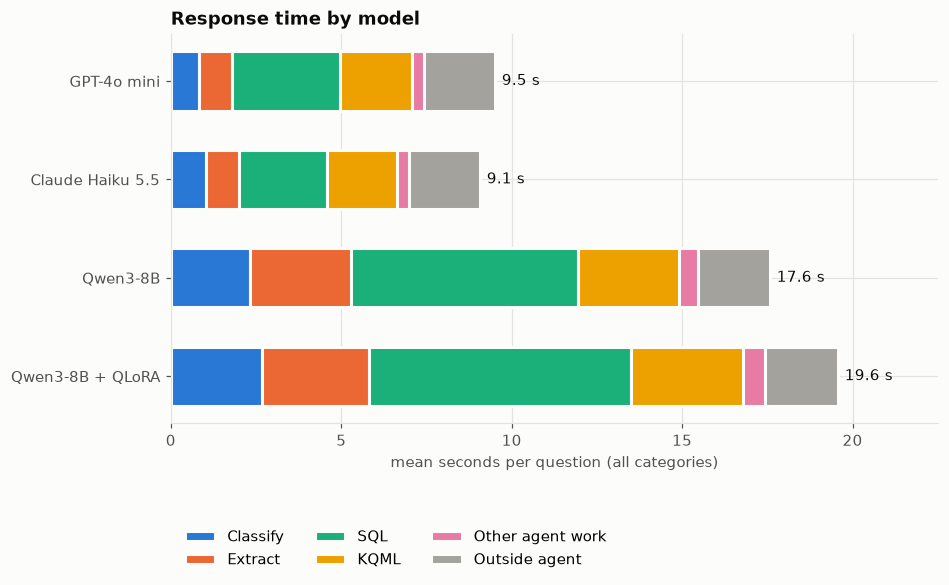

In [31]:
stacked_steps(by_model, MODELS, [MODEL_LABEL[m] for m in MODELS], "Response time by model",
              "mean seconds per question (all categories)", "time_by_model")

## 2. Response time by model and category

Mean seconds per question.

In [32]:
by_cat = df.pivot_table(index="category", columns="model", values="Total", aggfunc="mean", observed=True)[MODELS]
by_cat.columns = [MODEL_LABEL[m] for m in MODELS]
by_cat.round(2)

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
category,,,,
1 Data missingness,7.38,7.30,14.09,15.25
2 Geometry missingness,5.51,6.38,11.38,12.11
3 Constructive operations,9.71,9.25,16.81,19.10
4 Relationships,11.02,9.72,20.54,23.06
5 Query delegation,11.78,11.87,21.10,23.63


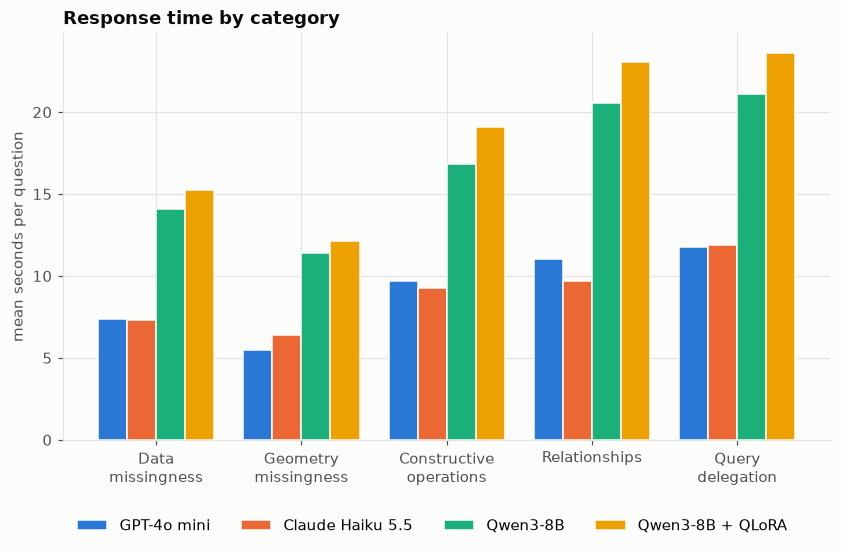

In [33]:
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
n = len(MODELS)
width = 0.8 / n
x = np.arange(len(CATEGORIES))
for i, m in enumerate(MODELS):
    ax.bar(x + (i - (n - 1) / 2) * width, by_cat[MODEL_LABEL[m]], width=width, color=MODEL_COLOR[m],
           label=MODEL_LABEL[m], edgecolor="#fcfcfb", linewidth=1)
ax.set_xticks(x, [c.split(" ", 1)[1].replace(" ", "\n", 1) for c in CATEGORIES])
ax.set_ylabel("mean seconds per question")
ax.grid(axis="y", color="#e4e3df")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title("Response time by category", loc="left", fontweight="bold")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.16), frameon=False)
fig.savefig(OUT_DIR / "time_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Where the time goes, by category

Mean seconds per question over all four models, split into the pipeline steps.

In [34]:
parts = df.groupby("category", observed=True)[STEP_LABELS + ["Total"]].mean()
parts["KQML share %"] = parts["KQML"] / parts["Total"] * 100
parts.round(2)

,Classify,Extract,SQL,KQML,Other agent work,Outside agent,Total,KQML share %
category,,,,,,,,
1 Data missingness,1.67,1.75,2.87,2.50,0.12,2.10,11.01,22.70
2 Geometry missingness,1.80,1.75,2.04,1.07,0.08,2.11,8.85,12.10
3 Constructive operations,1.69,2.09,4.94,2.73,0.17,2.10,13.72,19.86
4 Relationships,1.72,2.37,6.74,2.13,1.02,2.10,16.08,13.24
5 Query delegation,1.74,1.60,6.22,5.03,0.40,2.11,17.10,29.43


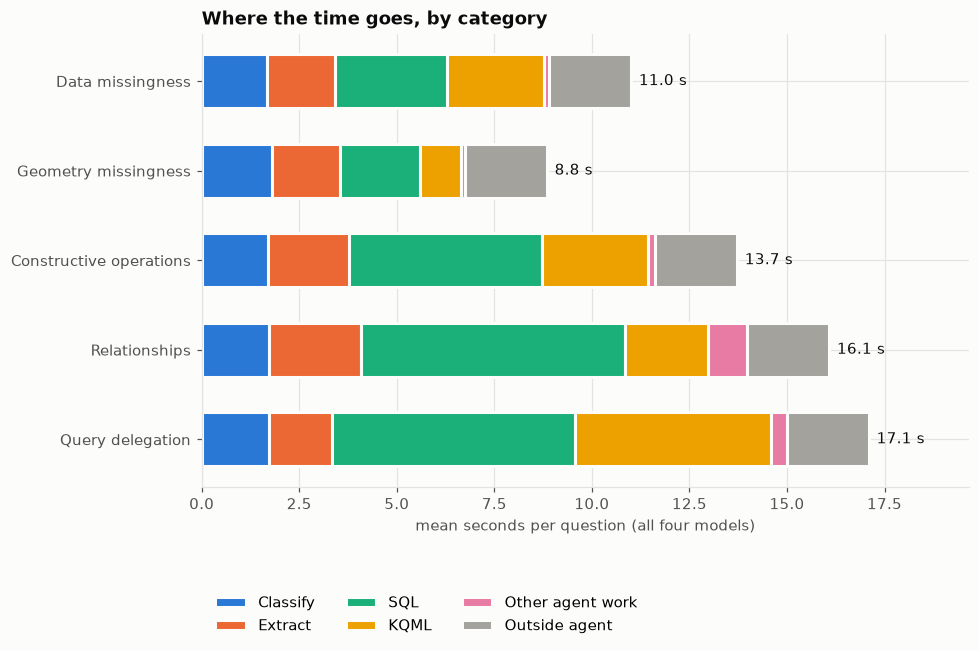

In [35]:
stacked_steps(parts, CATEGORIES, [c.split(" ", 1)[1] for c in CATEGORIES], "Where the time goes, by category",
              "mean seconds per question (all four models)", "time_parts_by_category")

## 4. What the numbers show

**By model**
* GPT-4o mini and Claude Haiku 5.5 answer in about 9–9.5 s per question, the Qwen models in about 17.5–19.5 s –
  roughly twice as long. The Qwen models ran on local hardware, so this compares the setups, not only the models.
* Qwen3-8B + QLoRA is about 2 s slower than the base Qwen3-8B, mostly in the SQL step (7.7 s vs 6.6 s).
* **SQL is the slowest step for every model** (2.6–7.7 s): writing the SQL, checking it, running it and retrying.
* The KQML exchange takes about 2.1 s for the API models and about 3 s for the Qwen models (the peer's model also
  has to run), which is 17–23 % of the total time.
* About 2.1 s of every question is spent outside the agent (HTTP and the test harness) – the same for every model.

**By category** – the order is almost the same for every model:
* **Geometry missingness** is the fastest (about 8.8 s): one lookup, and the shortest KQML exchange (1.1 s).
* **Data missingness** comes next (about 11 s).
* **Constructive operations, relationships and query delegation** take the longest (about 13.7–17.1 s): they need
  more SQL steps, so the SQL step alone takes 5–7 s.
* **Query delegation** spends the most time in KQML (5.0 s, 29 % of the total): the other agent runs the spatial test
  on its own cities before it can reply.

In [36]:
with pd.ExcelWriter(OUT_DIR / "response_time.xlsx") as xl:
    by_model.rename(index=MODEL_LABEL).round(3).to_excel(xl, sheet_name="by_model")
    by_cat.round(3).to_excel(xl, sheet_name="by_model_and_category")
    parts.round(3).to_excel(xl, sheet_name="parts_by_category")
print("saved to", OUT_DIR)

saved to outputs\02_response_time
